# 02 · Baselines, parte 1: identificación y selección (Fourier-ARIMA y SARIMA)

Muestra de identificación 2012-01-23 → 2020-12-28 (n=467), `y = log1p(hotspots)`, sin NaN. Grilla A: Fourier + ARMA (d=0). Grilla B: Fourier + ARIMA (d=1). Grilla C: SARIMA s=52, D=0, con los mejores (p,q) de A. El AIC/BIC solo es comparable dentro de cada grilla; entre A y B decide el backtest (fase 4).

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from fires import grids
from fires.backtest import RESULTS, load_series
from fires.models import fit_sarimax, make_fourier_arima

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
data = load_series()
y = data['y'].loc[:'2020-12-28']
print(len(y), y.isna().sum())

467 0


In [2]:
A = grids.run_grid('A', y, verbose=False)
B = grids.run_grid('B', y, verbose=False)
selA, selB = grids.select(A), grids.select(B)
print('A:', dict(selA[['K', 'trend', 'order', 'bic']])); print('B:', dict(selB[['K', 'trend', 'order', 'bic']]))

A: {'K': np.int64(2), 'trend': 'c', 'order': '(1, 0, 1)', 'bic': np.float64(1035.399755371958)}
B: {'K': np.int64(2), 'trend': 'n', 'order': '(0, 1, 2)', 'bic': np.float64(1023.0270948690741)}


In [3]:
C = grids.run_grid('C', y, best_pq=grids.best_pq_from(selA), verbose=False)
cands = pd.concat([A, B, C], ignore_index=True)
cands.to_csv(RESULTS / 'sarima_candidates.csv', index=False)
cols = ['K', 'trend', 'order', 'seasonal_order', 'aic', 'bic', 'converged', 'fit_seconds',
        'max_pvalue_arma', 'lb_p52', 'lb_p104']
C[cols].round(3)

,K,trend,order,seasonal_order,aic,bic,converged,fit_seconds,max_pvalue_arma,lb_p52,lb_p104
0,0,c,"(1, 0, 1)","(1, 0, 0, 52)",1122.703,1143.434,True,6.481,0.008,0.00,0.000
1,0,c,"(1, 0, 1)","(0, 0, 1, 52)",1124.399,1145.130,True,5.755,0.047,0.00,0.000
2,0,c,"(1, 0, 1)","(1, 0, 1, 52)",1094.114,1118.992,True,24.562,0.000,0.05,0.011


Grilla C: SARIMA con p,q de A, trend `c`, K=0.

In [4]:
print('fallos / no convergidos:', (~cands['converged']).sum(), 'de', len(cands))
for name, g in (('A', A), ('B', B)):
    q = g[g['converged'] & (g['max_pvalue_arma'] < 0.05)]
    print(name, 'pasan filtro (a):', len(q), 'de', len(g), '| tiempo total', round(g['fit_seconds'].sum()), 's')
    display(q.sort_values('bic').head(3)[cols + ['n_params']].round(3))

fallos / no convergidos: 6 de 93
A pasan filtro (a): 18 de 36 | tiempo total 55 s


,K,trend,order,seasonal_order,aic,bic,converged,fit_seconds,max_pvalue_arma,lb_p52,lb_p104,n_params
1,2,c,"(1, 0, 1)","(0, 0, 0, 0)",1002.229,1035.400,True,1.571,0.000,0.650,0.938,8
3,2,c,"(2, 0, 1)","(0, 0, 0, 0)",998.297,1035.614,True,3.528,0.002,0.761,0.938,9
5,2,c,"(3, 0, 1)","(0, 0, 0, 0)",995.384,1036.847,True,3.765,0.020,0.903,0.981,10


B pasan filtro (a): 34 de 54 | tiempo total 19 s


,K,trend,order,seasonal_order,aic,bic,converged,fit_seconds,max_pvalue_arma,lb_p52,lb_p104,n_params
2,2,n,"(0, 1, 2)","(0, 0, 0, 0)",994.018,1023.027,True,0.271,0.0,0.792,0.938,7
4,2,n,"(1, 1, 1)","(0, 0, 0, 0)",995.590,1024.600,True,0.324,0.0,0.746,0.927,7
1,2,n,"(0, 1, 1)","(0, 0, 0, 0)",1002.420,1027.285,True,0.153,0.0,0.443,0.881,6


In [5]:
# Seleccion: filtro (a), menor BIC, regla de dif < 2 -> el mas simple (menos parametros)
for name, sel in (('A', selA), ('B', selB)):
    print(name, dict(sel[['K', 'trend', 'order', 'bic', 'max_pvalue_arma', 'lb_p52', 'lb_p104']]))
specA, specB = grids.parse_spec(selA), grids.parse_spec(selB)
resA = fit_sarimax(y, specA[0], specA[1], specA[2])
resB = fit_sarimax(y, specB[0], specB[1], specB[2])
for name, r in (('A', resA), ('B', resB)):
    print(name); display(pd.DataFrame({'coef': r.params, 'se': r.bse, 'p': r.pvalues}).round(4))

A {'K': np.int64(2), 'trend': 'c', 'order': '(1, 0, 1)', 'bic': np.float64(1035.399755371958), 'max_pvalue_arma': np.float64(4.816648401263681e-98), 'lb_p52': np.float64(0.650138906256232), 'lb_p104': np.float64(0.9377050549704229)}
B {'K': np.int64(2), 'trend': 'n', 'order': '(0, 1, 2)', 'bic': np.float64(1023.0270948690741), 'max_pvalue_arma': np.float64(2.4085088969191884e-05), 'lb_p52': np.float64(0.7916748717689635), 'lb_p104': np.float64(0.9381313371293571)}


A


,coef,se,p
intercept,0.2472,0.1337,0.0645
sin_1,-1.7021,0.0909,0.0000
cos_1,-0.6288,0.0755,0.0000
sin_2,0.1707,0.0546,0.0018
cos_2,-0.2823,0.0601,0.0000
ar.L1,0.9652,0.0189,0.0000
ma.L1,-0.8126,0.0387,0.0000
sigma2,0.4830,0.0306,0.0000


B


,coef,se,p
sin_1,-1.6939,0.0698,0.0000
cos_1,-0.6302,0.0603,0.0000
sin_2,0.1740,0.0511,0.0007
cos_2,-0.2824,0.0600,0.0000
ma.L1,-0.7345,0.0418,0.0000
ma.L2,-0.1704,0.0404,0.0000
sigma2,0.4779,0.0299,0.0000


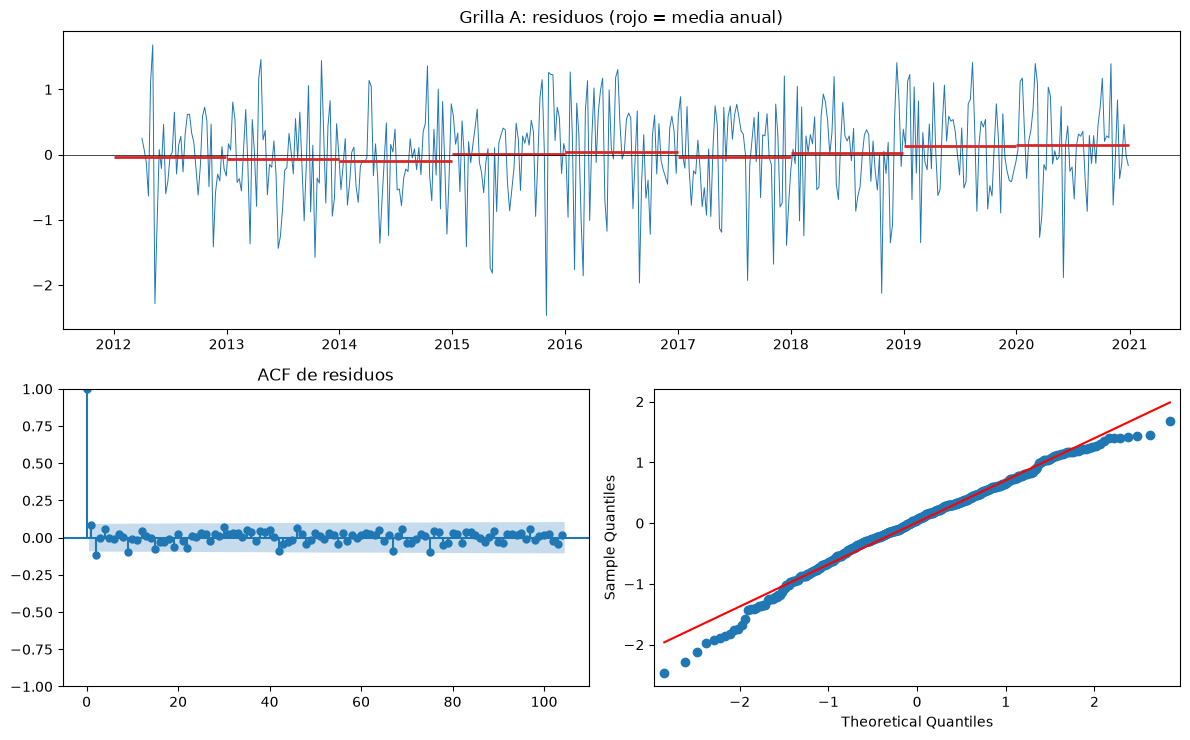

A media anual de residuos: {2012: -0.03, 2013: -0.07, 2014: -0.1, 2015: 0.01, 2016: 0.04, 2017: -0.04, 2018: 0.02, 2019: 0.13, 2020: 0.15}


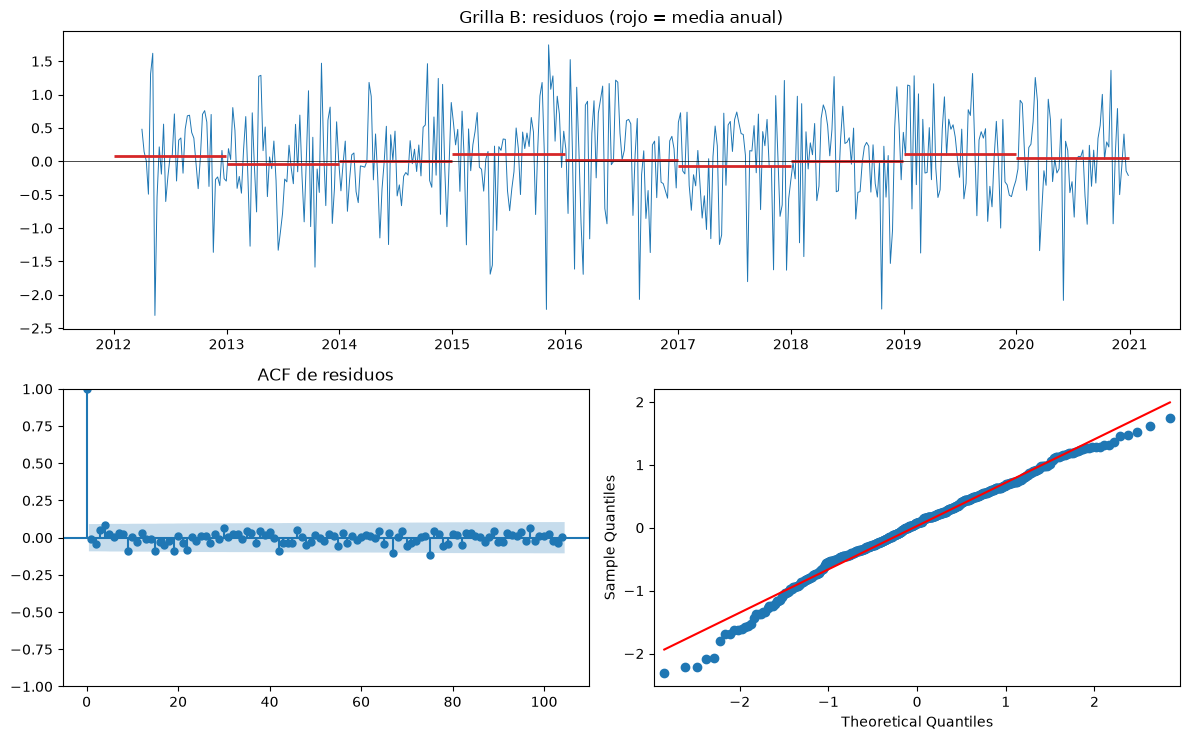

B media anual de residuos: {2012: 0.08, 2013: -0.03, 2014: 0.0, 2015: 0.11, 2016: 0.02, 2017: -0.07, 2018: 0.01, 2019: 0.11, 2020: 0.04}


In [6]:
for name, r in (('A', resA), ('B', resB)):
    fig, annual = grids.plot_resid(r, f'Grilla {name}', RESULTS / 'figures' / f'resid_{name}.png')
    plt.show()
    print(name, 'media anual de residuos:', annual.round(2).to_dict())

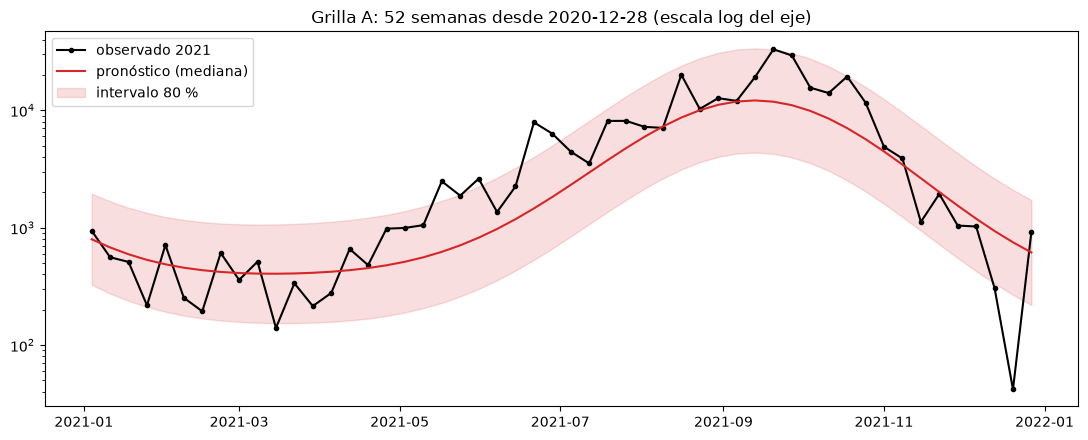

A suma pronosticada / observada 2021 = 0.59


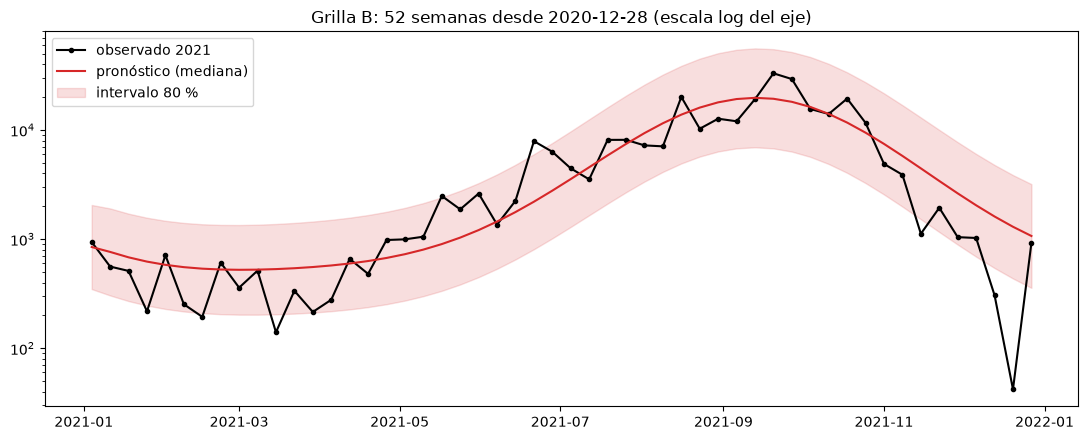

B suma pronosticada / observada 2021 = 0.95


In [7]:
for name, spec in (('A', specA), ('B', specB)):
    fig, tab = grids.plot_fc2021(y, data['hotspots'], spec, f'Grilla {name}', RESULTS / 'figures' / f'fc2021_{name}.png')
    plt.show()
    ratio = (tab['pred'].sum() / tab['obs'].sum())
    print(name, f'suma pronosticada / observada 2021 = {ratio:.2f}')

In [8]:
# Tiempo de un ajuste con la muestra completa (hasta 2025, con NaN) y h=12
full = data['y']
for name, spec in (('A', specA), ('B', specB)):
    f = make_fourier_arima(spec[0], spec[1], spec[2])
    t0 = time.perf_counter(); f(full, 12); print(name, round(time.perf_counter() - t0, 2), 's')

A 1.71 s


B 0.29 s
